Imports

In [ ]:
import heapq # To be able to use a priority queue
import networkx as nx # To build and draw the directed graph
import matplotlib.pyplot as plt # displays the diagram

Routes to "Kisumu"

In [ ]:
# Directed Graph
# Each node and its neighbour(s)
routes = {
    "Nairobi": {"Naivasha": 91, "Narok": 143},
    "Naivasha": {"Nakuru": 71},
    "Narok": {"Bomet": 81},
    "Nakuru": {"Eldoret": 156, "Kericho": 107},
    "Bomet": {"Litein": 44.1,"Kisii": 82.4},
    "Eldoret":{"Kisumu": 138},
    "Kericho":{"Kisumu": 84},
    "Litein":{"Kericho": 32},
    "Kisii":{"HomaBay": 52},
    "HomaBay":{"Kisumu": 108},
    "Kisumu":{},
}

Uniform Cost Search --> Function

In [ ]:
def uniform_cost_search(graph,start,goal):
  # Frontier: priority queue with....cost so far, current place, path taken
  # 'heapq' pops the cheapest, smallest tuple...i.e. cheapest cost comes first
  frontier = [(0, start, [start])]

  # Keeping record of Cheapest known cost to reaching the destination "Kisumu"
  best_cost = {start:0}

  while frontier:
    cost, place, path = heapq.heappop(frontier) # Pops the cheapest path

    #Test happens when POP, not when push, to be able to get the optimal path
    #If Kisumu is the current node, then the goal has been reached and optimal cost and path found
    if place == goal:
      return cost, path

    # Trying every posssible route leading out of current node
    for neighbour, route_cost in graph[place].items():
      new_cost = cost + route_cost

      # If this path is the only cheapest way found so far:
      if neighbour not in best_cost or new_cost < best_cost[neighbour]:
        best_cost[neighbour] = new_cost
        heapq.heappush(frontier, (new_cost, neighbour, path + [neighbour]))

  return None # If no route exists

cost, path = uniform_cost_search(routes,"Nairobi","Kisumu")
print("Least Cost route: ", " -> " .join(path))
print("Total cost: ", cost," km ")


Least Cost route:  Nairobi -> Naivasha -> Nakuru -> Kericho -> Kisumu
Total cost:  353  km 


Turning the routes dictionary to a directed graph

In [ ]:
# routes dictionary --> directed graph
G = nx.DiGraph()
for place, neighbours in routes. items():
  for neighbour, km in neighbours.items():
    G.add_edge(place, neighbour,weight=km)

# Splitting routes to highlight the optimal path and to leave the rest as is
path_edges = list(zip(path,path[1:]))
other_edges = [e for e in G.edges() ]

# Our Color choice for the directed graph
# Light blue - Optimal path
# Light grey - Alternate paths
node_colors = ["lightskyblue" if town in path else "lightgray" for town in G.nodes()]

Positioning and Plotting the towns and paths

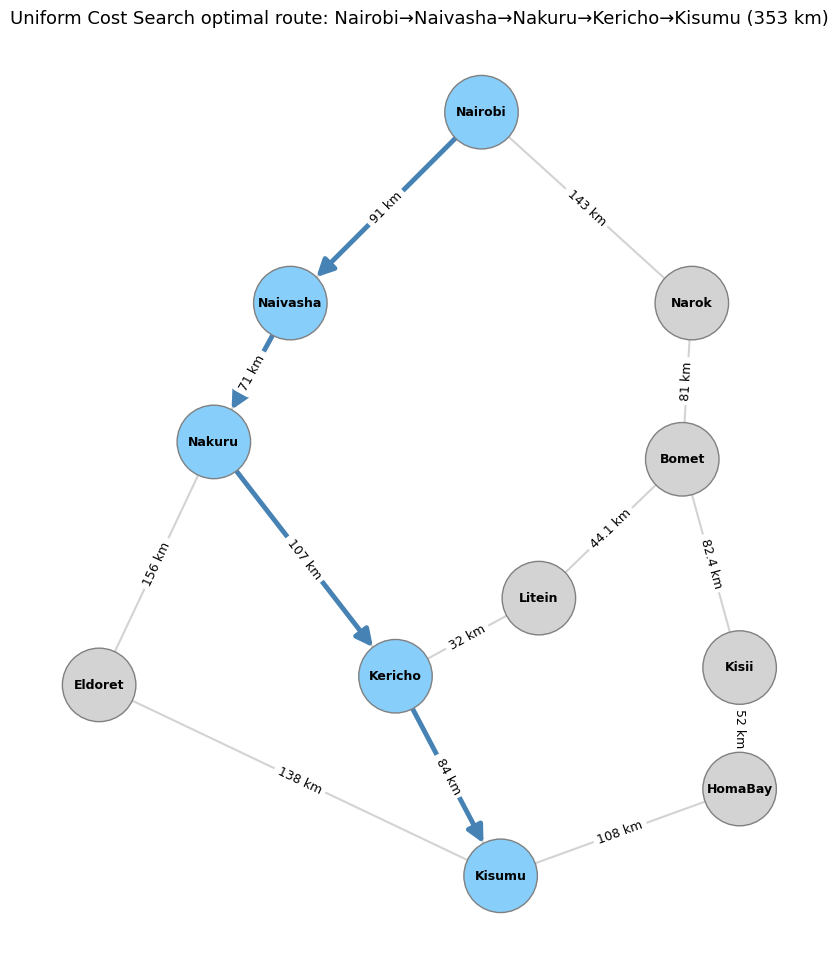

In [ ]:
# Positioning of towns to match the Lucidchart plot for initial ex 3A
pos={
    "Nairobi": (5.7, -1.9),
    "Naivasha": (3.7, -4.1),
    "Narok": (7.9, -4.1),
    "Nakuru": (2.9, -5.7),
    "Bomet": (7.8, -5.9),
    "Litein": (6.3, -7.5),
    "Kisii": (8.4, -8.3),
    "Eldoret": (1.7, -8.5),
    "Kericho": (4.8, -8.4),
    "HomaBay": (8.4, -9.7),
    "Kisumu": (5.9, -10.7),
}

plt.figure(figsize=(10,12))

# 1. Other roads(grey):
nx.draw_networkx_edges(G, pos, edgelist=other_edges,
                       edge_color="lightgray", width=1.5, arrows=False)

# 2. Optimal Path(bold arrows):
nx.draw_networkx_edges(G, pos, edgelist=path_edges,
                       edge_color="steelblue", width=3.5, arrows=True,
                       arrowstyle="-|>", arrowsize=25, node_size=2800)

# 3. Towns, coloured if on the optimal path otherwise, gray
nx.draw_networkx_nodes(G,pos, node_color=node_colors,
                       node_size=2800, edgecolors="gray")
nx.draw_networkx_labels(G, pos, font_size=9, font_weight="bold")

# 4. Distances for every sub-route
edge_labels = {(u,v): f"{d['weight']:g} km" for u, v , d in G.edges(data=True)}
nx.draw_networkx_edge_labels(G,pos, edge_labels=edge_labels, font_size=9)

plt.title(f"Uniform Cost Search optimal route: {'→'.join(path)} ({cost:g} km)", fontsize=13)
plt.axis("off")
plt.show()